# CS 725 · Hinglish sentiment · Classical baselines and first results

This notebook gets the data, runs the four classical models, and makes the first results for our research questions.

| Section | What it does | Who |
|---|---|---|
| 1-2 | Get the code and the data | everyone |
| 3 | Check the code, look at cleaning and the spelling dictionary | everyone, Person 2 reviews the dictionary |
| 4 | Run the models, **one subsection per person** | each person runs their own subsection |
| 5 | All results in one table: progress towards 24 runs | anyone |
| 6 | First results for Q1 (normalization) and Q2 (which tweets fail) | Q1 Person 2, Q2 Persons 1 and 4 |

* Works on a laptop, Colab or Kaggle. No GPU is needed.
* Results are printed in the notebook **and** saved in `results/`, so they can be committed.

## 1. Get the code
Finds the project folder if you already have it (local run). Clones only if it isn't there yet (Colab/Kaggle). Safe to re-run: it never creates a new folder twice.

In [1]:
import os
from pathlib import Path

LOCAL = Path("/Users/kartheek/Desktop/IITB Files/FML/cs725-hinglish-sentiment")   # your laptop
COLAB = Path("/content/Hinglish-sentiment-analysis")  # Google Colab

if LOCAL.exists():
    os.chdir(LOCAL)
else:
    if not COLAB.exists():
        !git clone -q https://github.com/Kartheek-pallem/Hinglish-sentiment-analysis.git /content/Hinglish-sentiment-analysis
    os.chdir(COLAB)

print("Working in:", Path.cwd())

Working in: /Users/kartheek/Desktop/IITB Files/FML/cs725-hinglish-sentiment


In [2]:
%pip install -q -r requirements.txt

You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


## 2. Download SentiMix and build the CSVs
Expect 14,000 / 3,000 / 3,000 tweets and **ALL CHECKS PASSED** at the end. If any check needs a look, post the output in the group chat.

In [3]:
!python3 -m src.data

Parsing and checking ...
  [train_14k_split_conll.txt] empty token skipped: 32
  [dev_3k_split_conll.txt] empty token skipped: 2
  [Hindi_test_unalbelled_conll_updated.txt] empty token skipped: 4
  test: 0 tweets without a label, 0 labels without a tweet
  train:  14000 tweets (OK); duplicate ids: 0; unknown labels: none
         class balance: {'neutral': 0.376, 'positive': 0.331, 'negative': 0.293}
  val  :   3000 tweets (OK); duplicate ids: 0; unknown labels: none
         class balance: {'neutral': 0.376, 'positive': 0.327, 'negative': 0.297}
  test :   3000 tweets (OK); duplicate ids: 0; unknown labels: none
         class balance: {'neutral': 0.367, 'positive': 0.333, 'negative': 0.3}
  word tags: 522563 tokens; share by tag: {'Hin': 0.465, 'Eng': 0.332, 'O': 0.202, 'EMT': 0.001}
  ALL CHECKS PASSED


## 3. Check the code and the preprocessing

### 3.1 Run the tests
Expect **`Ran 17 tests ... OK`** at the end. Lines saying *SOME CHECKS NEED A LOOK* come from the tiny made-up test files and are expected.

In [4]:
!python3 -m unittest discover -s tests

  [train_14k_split_conll.txt] empty token skipped: 1
  [train_14k_split_conll.txt] missing or unknown tag set to O: 1
  [dev_3k_split_conll.txt] empty token skipped: 1
  [dev_3k_split_conll.txt] missing or unknown tag set to O: 1
  test: 0 tweets without a label, 0 labels without a tweet
  train:      3 tweets (EXPECTED 14000); duplicate ids: 0; unknown labels: none
         class balance: {'positive': 0.333, 'neutral': 0.333, 'negative': 0.333}
  val  :      3 tweets (EXPECTED 3000); duplicate ids: 0; unknown labels: none
         class balance: {'positive': 0.333, 'neutral': 0.333, 'negative': 0.333}
  test :      2 tweets (EXPECTED 3000); duplicate ids: 0; unknown labels: none
         class balance: {'positive': 0.5, 'negative': 0.5}
  word tags: 34 tokens; share by tag: {'Hin': 0.471, 'Eng': 0.353, 'O': 0.118, 'EMT': 0.059}
  SOME CHECKS NEED A LOOK (see above)
.../Users/kartheek/Library/Python/3.9/lib/python/site-packages/matplotlib/_fontconfig_pattern.py:64: PyparsingDeprecation

### 3.2 What `clean()` does
Removes links and user names, lower-cases, shortens stretched letters (*yaaaar → yaar*), and repairs broken characters.
The test file was saved with the wrong encoding (*…* appears as *â€¦*, 😂 as *ðŸ˜‚*), so the last line should say about **70% before, 0% after** for test.

In [5]:
!python3 -m src.clean


=== train: 5 examples ===
BEFORE: Smirti ji ko phir ek BAr phir mantri bnana par sabhi dasvasiyo ki taraf sa dil sa Abhinandan Asa karta hu ki jaisa … https // t . co / 0QS1DXNjs5
AFTER:  smirti ji ko phir ek bar phir mantri bnana par sabhi dasvasiyo ki taraf sa dil sa abhinandan asa karta hu ki jaisa … 

BEFORE: RT @ NishaSi95237904 Koi v yaisa lamha nahi hai Jisme mere tu hota nahi h # KYYS4OnVootWithPaNiAsMaNan @ anupkofficial @ justvoot @ BBCStudi …
AFTER:  koi v yaisa lamha nahi hai jisme mere tu hota nahi h kyys4onvootwithpaniasmanan … 

BEFORE: Finally jab apka Nikkah apke Crush sy hojae https // tco / AV619JpxV6
AFTER:  finally jab apka nikkah apke crush sy hojae 

BEFORE: RT @ pranav _ bodani @ ashwinravi99 @ WorcsCCC Na ishq me na Pyar me Jo maza hai king Kohli ki har me
AFTER:  na ishq me na pyar me jo maza hai king kohli ki har me 

BEFORE: @ ramsarnacharya1 @ ZeeNewsHindi Swami ji karmo ka fal jaroor milta hai chinta na Kare . Apne acche karm kiye apna dha … https // t . 

### 3.3 The spelling dictionary (Person 2 reviews this before the *normalized* runs)
`data/lexicon/norm_dict.csv` maps spelling variants to one form (*nhi → nahi*, *bht → bahut*), sorted by how often they appear.
Open it, read the top 200 rows, and put **0 in the `keep` column** of any pair that joins two different words (e.g. *haar* "defeat" → *har* "every"). Then re-run the cell below.
The cell prints the top rows and how many test words each dictionary size changes.

In [7]:
!python3 -m src.normalize

import pandas as pd
lex = pd.read_csv("data/lexicon/norm_dict.csv")
print(f"{len(lex)} pairs, {int((lex.keep == 0).sum())} switched off (keep = 0):")
print(lex[lex.keep == 0][["variant", "canonical", "variant_count"]].to_string(index=False))


rank  variant      -> canonical    times seen  source
   1  nhi          -> nahi                725  seed
   2  kr           -> kar                 400  seed
   3  pr           -> par                 196  seed
   4  kyu          -> kyun                188  seed
   5  kam          -> kaam                161  auto: same sound
   6  apko         -> aapko               148  auto: same sound
   7  bar          -> baar                136  auto: same sound
   8  nai          -> nahi                119  seed
   9  fir          -> phir                115  auto: same sound
  10  baad         -> bad                 102  auto: same sound   (keep=0, skipped)
  11  app          -> aap                  96  auto: same sound
  12  bhut         -> bahut                96  seed
  13  gya          -> gaya                 95  auto: vowels dropped
  14  saale        -> sale                 91  auto: same sound
  15  apke         -> aapke                89  auto: same sound
  16  rhe          -> rahe       

## 4. Run the models
Each person runs **their own subsection**. Every model gets six runs: three text versions (raw, cleaned, normalized) × two feature types (word, char).
`--tune` picks the setting on **validation**, then scores the test set once.

Run the cell just below first: it defines `show()`, which prints a table of a model's test results so far.

In [8]:
import sys; sys.path.insert(0, ".")
import pandas as pd
from IPython.display import display
from src.evaluate import load_results

pd.set_option("display.max_colwidth", 60)


def show(model):
    """Test results of one model so far: one row per run, best first."""
    res = load_results()
    t = res[(res.model == model) & (res.dataset == "sentimix_test")].drop_duplicates("run_id", keep="last").copy()
    if t.empty:
        print(f"no test runs for {model} yet")
        return
    t["dict_size"] = t.dict_size.fillna("").astype(str).str.replace(".0", "", regex=False)
    cols = ["owner", "preprocessing", "features", "dict_size", "macro_f1", "accuracy",
            "f1_negative", "f1_neutral", "f1_positive", "notes"]
    display(t[cols].sort_values("macro_f1", ascending=False).reset_index(drop=True))

### 4.1 Person 1 (Mahesh) · Logistic regression
**Raw text** (already done):

In [9]:
!python3 scripts/baseline_lr.py --owner person1        # first run: default C = 1

train 14000 tweets, 42618 features (word)
person1_logreg_sentimix-val_raw_word: macro-F1 0.6167 | accuracy 0.6127 | F1 neg/neu/pos 0.644/0.534/0.672
person1_logreg_sentimix-test_raw_word: macro-F1 0.6762 | accuracy 0.6720 | F1 neg/neu/pos 0.695/0.594/0.740


In [10]:
!python3 scripts/baseline_lr.py --owner person1 --tune

train 14000 tweets, 42618 features (word)
person1_logreg_sentimix-val_raw_word: macro-F1 0.5895 | accuracy 0.5847 | F1 neg/neu/pos 0.591/0.528/0.650
person1_logreg_sentimix-val_raw_word: macro-F1 0.6106 | accuracy 0.6060 | F1 neg/neu/pos 0.622/0.532/0.677
person1_logreg_sentimix-val_raw_word: macro-F1 0.6167 | accuracy 0.6127 | F1 neg/neu/pos 0.644/0.534/0.672
person1_logreg_sentimix-val_raw_word: macro-F1 0.6126 | accuracy 0.6083 | F1 neg/neu/pos 0.647/0.526/0.664
person1_logreg_sentimix-val_raw_word: macro-F1 0.6019 | accuracy 0.5973 | F1 neg/neu/pos 0.643/0.514/0.648
best C on validation: 1 (macro-F1 0.6167)
person1_logreg_sentimix-val_raw_word: macro-F1 0.6167 | accuracy 0.6127 | F1 neg/neu/pos 0.644/0.534/0.672
person1_logreg_sentimix-test_raw_word: macro-F1 0.6762 | accuracy 0.6720 | F1 neg/neu/pos 0.695/0.594/0.740


In [11]:
!python3 scripts/baseline_lr.py --owner person1 --tune --features char

train 14000 tweets, 122301 features (char)
person1_logreg_sentimix-val_raw_char: macro-F1 0.6084 | accuracy 0.6043 | F1 neg/neu/pos 0.603/0.562/0.660
person1_logreg_sentimix-val_raw_char: macro-F1 0.6164 | accuracy 0.6120 | F1 neg/neu/pos 0.626/0.559/0.665
person1_logreg_sentimix-val_raw_char: macro-F1 0.6164 | accuracy 0.6123 | F1 neg/neu/pos 0.631/0.550/0.669
person1_logreg_sentimix-val_raw_char: macro-F1 0.6063 | accuracy 0.6023 | F1 neg/neu/pos 0.629/0.529/0.660
person1_logreg_sentimix-val_raw_char: macro-F1 0.5889 | accuracy 0.5847 | F1 neg/neu/pos 0.618/0.510/0.638
best C on validation: 0.3 (macro-F1 0.6164)
person1_logreg_sentimix-val_raw_char: macro-F1 0.6164 | accuracy 0.6120 | F1 neg/neu/pos 0.626/0.559/0.665
person1_logreg_sentimix-test_raw_char: macro-F1 0.6716 | accuracy 0.6660 | F1 neg/neu/pos 0.694/0.602/0.719


**Cleaned and normalized text** (new):

In [13]:
!python3 scripts/baseline_lr.py --owner person1 --tune --preprocessing cleaned

train 14000 tweets, 36145 features (word, cleaned)
person1_logreg_sentimix-val_cleaned_word: macro-F1 0.5983 | accuracy 0.5933 | F1 neg/neu/pos 0.607/0.530/0.657
person1_logreg_sentimix-val_cleaned_word: macro-F1 0.6112 | accuracy 0.6070 | F1 neg/neu/pos 0.631/0.526/0.676
person1_logreg_sentimix-val_cleaned_word: macro-F1 0.6088 | accuracy 0.6050 | F1 neg/neu/pos 0.640/0.517/0.670
person1_logreg_sentimix-val_cleaned_word: macro-F1 0.6030 | accuracy 0.5993 | F1 neg/neu/pos 0.643/0.513/0.653
person1_logreg_sentimix-val_cleaned_word: macro-F1 0.5902 | accuracy 0.5863 | F1 neg/neu/pos 0.639/0.495/0.637
best C on validation: 0.3 (macro-F1 0.6112)
person1_logreg_sentimix-val_cleaned_word: macro-F1 0.6112 | accuracy 0.6070 | F1 neg/neu/pos 0.631/0.526/0.676
person1_logreg_sentimix-test_cleaned_word: macro-F1 0.6667 | accuracy 0.6627 | F1 neg/neu/pos 0.681/0.584/0.735


In [14]:
!python3 scripts/baseline_lr.py --owner person1 --tune --preprocessing cleaned --features char

train 14000 tweets, 67801 features (char, cleaned)
person1_logreg_sentimix-val_cleaned_char: macro-F1 0.6118 | accuracy 0.6073 | F1 neg/neu/pos 0.613/0.550/0.672
person1_logreg_sentimix-val_cleaned_char: macro-F1 0.6212 | accuracy 0.6170 | F1 neg/neu/pos 0.632/0.555/0.677
person1_logreg_sentimix-val_cleaned_char: macro-F1 0.6227 | accuracy 0.6187 | F1 neg/neu/pos 0.643/0.549/0.675
person1_logreg_sentimix-val_cleaned_char: macro-F1 0.6072 | accuracy 0.6030 | F1 neg/neu/pos 0.641/0.532/0.649
person1_logreg_sentimix-val_cleaned_char: macro-F1 0.5931 | accuracy 0.5890 | F1 neg/neu/pos 0.636/0.517/0.626
best C on validation: 1 (macro-F1 0.6227)
person1_logreg_sentimix-val_cleaned_char: macro-F1 0.6227 | accuracy 0.6187 | F1 neg/neu/pos 0.643/0.549/0.675
person1_logreg_sentimix-test_cleaned_char: macro-F1 0.6839 | accuracy 0.6790 | F1 neg/neu/pos 0.705/0.612/0.735


In [15]:
!python3 scripts/baseline_lr.py --owner person1 --tune --preprocessing normalized

train 14000 tweets, 35687 features (word, normalized)
person1_logreg_sentimix-val_normalized_word_dall: macro-F1 0.6007 | accuracy 0.5960 | F1 neg/neu/pos 0.606/0.532/0.664
person1_logreg_sentimix-val_normalized_word_dall: macro-F1 0.6127 | accuracy 0.6087 | F1 neg/neu/pos 0.630/0.526/0.682
person1_logreg_sentimix-val_normalized_word_dall: macro-F1 0.6069 | accuracy 0.6030 | F1 neg/neu/pos 0.636/0.513/0.671
person1_logreg_sentimix-val_normalized_word_dall: macro-F1 0.6040 | accuracy 0.6003 | F1 neg/neu/pos 0.641/0.510/0.661
person1_logreg_sentimix-val_normalized_word_dall: macro-F1 0.5949 | accuracy 0.5907 | F1 neg/neu/pos 0.641/0.500/0.644
best C on validation: 0.3 (macro-F1 0.6127)
person1_logreg_sentimix-val_normalized_word_dall: macro-F1 0.6127 | accuracy 0.6087 | F1 neg/neu/pos 0.630/0.526/0.682
person1_logreg_sentimix-test_normalized_word_dall: macro-F1 0.6685 | accuracy 0.6647 | F1 neg/neu/pos 0.680/0.586/0.739


In [16]:
!python3 scripts/baseline_lr.py --owner person1 --tune --preprocessing normalized --features char

train 14000 tweets, 66596 features (char, normalized)
person1_logreg_sentimix-val_normalized_char_dall: macro-F1 0.6150 | accuracy 0.6107 | F1 neg/neu/pos 0.616/0.554/0.674
person1_logreg_sentimix-val_normalized_char_dall: macro-F1 0.6215 | accuracy 0.6173 | F1 neg/neu/pos 0.634/0.554/0.677
person1_logreg_sentimix-val_normalized_char_dall: macro-F1 0.6195 | accuracy 0.6157 | F1 neg/neu/pos 0.641/0.545/0.672
person1_logreg_sentimix-val_normalized_char_dall: macro-F1 0.6096 | accuracy 0.6057 | F1 neg/neu/pos 0.641/0.536/0.653
person1_logreg_sentimix-val_normalized_char_dall: macro-F1 0.5888 | accuracy 0.5847 | F1 neg/neu/pos 0.632/0.511/0.623
best C on validation: 0.3 (macro-F1 0.6215)
person1_logreg_sentimix-val_normalized_char_dall: macro-F1 0.6215 | accuracy 0.6173 | F1 neg/neu/pos 0.634/0.554/0.677
person1_logreg_sentimix-test_normalized_char_dall: macro-F1 0.6904 | accuracy 0.6853 | F1 neg/neu/pos 0.708/0.626/0.737


**Results so far:**

In [17]:
show("logreg")

,owner,preprocessing,features,dict_size,macro_f1,accuracy,f1_negative,f1_neutral,f1_positive,notes
0,person1,normalized,char,all,0.6904,0.6853,0.7084,0.6261,0.7368,C=0.3
1,person1,cleaned,char,,0.6839,0.6790,0.7049,0.6118,0.7348,C=1
2,person1,raw,word,,0.6762,0.6720,0.6951,0.5937,0.7398,C=1
3,person2,raw,word,,0.6762,0.6720,0.6951,0.5937,0.7398,C=1.0
4,person1,raw,char,,0.6716,0.6660,0.6937,0.6019,0.7192,C=0.3
5,person1,normalized,word,all,0.6685,0.6647,0.6805,0.5861,0.7390,C=0.3
6,person1,cleaned,word,,0.6667,0.6627,0.6809,0.5839,0.7354,C=0.3


### 4.2 Person 2 (Manikanta) · Linear SVM
**Raw text** (already done):

In [19]:
!python3 scripts/svm.py --owner person2              # first run: default C = 1

train 14000 tweets, 42618 features (word, raw)
person2_svm_sentimix-val_raw_word: macro-F1 0.6013 | accuracy 0.5970 | F1 neg/neu/pos 0.640/0.512/0.652
person2_svm_sentimix-test_raw_word: macro-F1 0.6396 | accuracy 0.6357 | F1 neg/neu/pos 0.666/0.548/0.704


In [20]:
!python3 scripts/svm.py --owner person2 --tune # pick C on validation, then test once

train 14000 tweets, 42618 features (word, raw)
person2_svm_sentimix-val_raw_word: macro-F1 0.5811 | accuracy 0.5777 | F1 neg/neu/pos 0.565/0.528/0.650
person2_svm_sentimix-val_raw_word: macro-F1 0.6033 | accuracy 0.5997 | F1 neg/neu/pos 0.621/0.517/0.672
person2_svm_sentimix-val_raw_word: macro-F1 0.6121 | accuracy 0.6087 | F1 neg/neu/pos 0.641/0.519/0.676
person2_svm_sentimix-val_raw_word: macro-F1 0.6110 | accuracy 0.6073 | F1 neg/neu/pos 0.647/0.520/0.666
person2_svm_sentimix-val_raw_word: macro-F1 0.6013 | accuracy 0.5970 | F1 neg/neu/pos 0.640/0.512/0.652
person2_svm_sentimix-val_raw_word: macro-F1 0.5838 | accuracy 0.5797 | F1 neg/neu/pos 0.623/0.502/0.626
best C on validation: 0.1 (macro-F1 0.6121)
person2_svm_sentimix-val_raw_word: macro-F1 0.6121 | accuracy 0.6087 | F1 neg/neu/pos 0.641/0.519/0.676
person2_svm_sentimix-test_raw_word: macro-F1 0.6765 | accuracy 0.6730 | F1 neg/neu/pos 0.701/0.587/0.742


In [21]:
!python3 scripts/svm.py --owner person2 --tune --features char

train 14000 tweets, 122301 features (char, raw)
person2_svm_sentimix-val_raw_char: macro-F1 0.6040 | accuracy 0.6007 | F1 neg/neu/pos 0.594/0.559/0.659
person2_svm_sentimix-val_raw_char: macro-F1 0.6199 | accuracy 0.6160 | F1 neg/neu/pos 0.635/0.555/0.669
person2_svm_sentimix-val_raw_char: macro-F1 0.6207 | accuracy 0.6170 | F1 neg/neu/pos 0.635/0.550/0.676
person2_svm_sentimix-val_raw_char: macro-F1 0.6120 | accuracy 0.6087 | F1 neg/neu/pos 0.628/0.538/0.670
person2_svm_sentimix-val_raw_char: macro-F1 0.5982 | accuracy 0.5947 | F1 neg/neu/pos 0.628/0.519/0.648
person2_svm_sentimix-val_raw_char: macro-F1 0.5806 | accuracy 0.5767 | F1 neg/neu/pos 0.620/0.498/0.624
best C on validation: 0.1 (macro-F1 0.6207)
person2_svm_sentimix-val_raw_char: macro-F1 0.6207 | accuracy 0.6170 | F1 neg/neu/pos 0.635/0.550/0.676
person2_svm_sentimix-test_raw_char: macro-F1 0.6826 | accuracy 0.6780 | F1 neg/neu/pos 0.710/0.605/0.733


**Cleaned and normalized text** (new). Start the normalized runs after the dictionary review in 3.3:

In [22]:
!python3 scripts/svm.py --owner person2 --tune --preprocessing cleaned

train 14000 tweets, 36145 features (word, cleaned)
person2_svm_sentimix-val_cleaned_word: macro-F1 0.5877 | accuracy 0.5837 | F1 neg/neu/pos 0.584/0.526/0.652
person2_svm_sentimix-val_cleaned_word: macro-F1 0.6056 | accuracy 0.6023 | F1 neg/neu/pos 0.631/0.513/0.673
person2_svm_sentimix-val_cleaned_word: macro-F1 0.6121 | accuracy 0.6093 | F1 neg/neu/pos 0.640/0.515/0.681
person2_svm_sentimix-val_cleaned_word: macro-F1 0.6057 | accuracy 0.6027 | F1 neg/neu/pos 0.643/0.511/0.663
person2_svm_sentimix-val_cleaned_word: macro-F1 0.5970 | accuracy 0.5933 | F1 neg/neu/pos 0.643/0.503/0.644
person2_svm_sentimix-val_cleaned_word: macro-F1 0.5798 | accuracy 0.5760 | F1 neg/neu/pos 0.632/0.489/0.618
best C on validation: 0.1 (macro-F1 0.6121)
person2_svm_sentimix-val_cleaned_word: macro-F1 0.6121 | accuracy 0.6093 | F1 neg/neu/pos 0.640/0.515/0.681
person2_svm_sentimix-test_cleaned_word: macro-F1 0.6701 | accuracy 0.6667 | F1 neg/neu/pos 0.688/0.579/0.743


In [23]:
!python3 scripts/svm.py --owner person2 --tune --preprocessing cleaned --features char

train 14000 tweets, 67801 features (char, cleaned)
person2_svm_sentimix-val_cleaned_char: macro-F1 0.6079 | accuracy 0.6040 | F1 neg/neu/pos 0.610/0.541/0.673
person2_svm_sentimix-val_cleaned_char: macro-F1 0.6172 | accuracy 0.6137 | F1 neg/neu/pos 0.632/0.540/0.679
person2_svm_sentimix-val_cleaned_char: macro-F1 0.6281 | accuracy 0.6247 | F1 neg/neu/pos 0.648/0.553/0.683
person2_svm_sentimix-val_cleaned_char: macro-F1 0.6149 | accuracy 0.6117 | F1 neg/neu/pos 0.640/0.534/0.670
person2_svm_sentimix-val_cleaned_char: macro-F1 0.5970 | accuracy 0.5933 | F1 neg/neu/pos 0.639/0.518/0.634
person2_svm_sentimix-val_cleaned_char: macro-F1 0.5781 | accuracy 0.5747 | F1 neg/neu/pos 0.625/0.505/0.604
best C on validation: 0.1 (macro-F1 0.6281)
person2_svm_sentimix-val_cleaned_char: macro-F1 0.6281 | accuracy 0.6247 | F1 neg/neu/pos 0.648/0.553/0.683
person2_svm_sentimix-test_cleaned_char: macro-F1 0.6909 | accuracy 0.6867 | F1 neg/neu/pos 0.711/0.617/0.745


In [24]:
!python3 scripts/svm.py --owner person2 --tune --preprocessing normalized

train 14000 tweets, 35687 features (word, normalized)
person2_svm_sentimix-val_normalized_word_dall: macro-F1 0.5894 | accuracy 0.5857 | F1 neg/neu/pos 0.584/0.523/0.661
person2_svm_sentimix-val_normalized_word_dall: macro-F1 0.6023 | accuracy 0.5997 | F1 neg/neu/pos 0.627/0.505/0.675
person2_svm_sentimix-val_normalized_word_dall: macro-F1 0.6081 | accuracy 0.6057 | F1 neg/neu/pos 0.633/0.507/0.684
person2_svm_sentimix-val_normalized_word_dall: macro-F1 0.6039 | accuracy 0.6010 | F1 neg/neu/pos 0.641/0.502/0.669
person2_svm_sentimix-val_normalized_word_dall: macro-F1 0.5978 | accuracy 0.5940 | F1 neg/neu/pos 0.648/0.502/0.643
person2_svm_sentimix-val_normalized_word_dall: macro-F1 0.5846 | accuracy 0.5807 | F1 neg/neu/pos 0.636/0.495/0.622
best C on validation: 0.1 (macro-F1 0.6081)
person2_svm_sentimix-val_normalized_word_dall: macro-F1 0.6081 | accuracy 0.6057 | F1 neg/neu/pos 0.633/0.507/0.684
person2_svm_sentimix-test_normalized_word_dall: macro-F1 0.6781 | accuracy 0.6753 | F1 neg

In [25]:
!python3 scripts/svm.py --owner person2 --tune --preprocessing normalized --features char

train 14000 tweets, 66596 features (char, normalized)
person2_svm_sentimix-val_normalized_char_dall: macro-F1 0.6121 | accuracy 0.6087 | F1 neg/neu/pos 0.614/0.547/0.675
person2_svm_sentimix-val_normalized_char_dall: macro-F1 0.6201 | accuracy 0.6167 | F1 neg/neu/pos 0.635/0.543/0.682
person2_svm_sentimix-val_normalized_char_dall: macro-F1 0.6271 | accuracy 0.6240 | F1 neg/neu/pos 0.646/0.547/0.689
person2_svm_sentimix-val_normalized_char_dall: macro-F1 0.6192 | accuracy 0.6160 | F1 neg/neu/pos 0.646/0.540/0.671
person2_svm_sentimix-val_normalized_char_dall: macro-F1 0.5972 | accuracy 0.5937 | F1 neg/neu/pos 0.639/0.518/0.634
person2_svm_sentimix-val_normalized_char_dall: macro-F1 0.5774 | accuracy 0.5740 | F1 neg/neu/pos 0.620/0.502/0.611
best C on validation: 0.1 (macro-F1 0.6271)
person2_svm_sentimix-val_normalized_char_dall: macro-F1 0.6271 | accuracy 0.6240 | F1 neg/neu/pos 0.646/0.547/0.689
person2_svm_sentimix-test_normalized_char_dall: macro-F1 0.6905 | accuracy 0.6860 | F1 neg

**How big must the dictionary be?** (for Q1) The best model, run again with only the top 50, 100 and 200 dictionary pairs.
Cleaned text counts as size 0, and the run above is the full dictionary.

In [26]:
!python3 scripts/svm.py --owner person2 --tune --preprocessing normalized --features char --dict-size 50
!python3 scripts/svm.py --owner person2 --tune --preprocessing normalized --features char --dict-size 100
!python3 scripts/svm.py --owner person2 --tune --preprocessing normalized --features char --dict-size 200

train 14000 tweets, 67744 features (char, normalized)
person2_svm_sentimix-val_normalized_char_d50: macro-F1 0.6092 | accuracy 0.6057 | F1 neg/neu/pos 0.610/0.542/0.675
person2_svm_sentimix-val_normalized_char_d50: macro-F1 0.6180 | accuracy 0.6147 | F1 neg/neu/pos 0.634/0.540/0.680
person2_svm_sentimix-val_normalized_char_d50: macro-F1 0.6256 | accuracy 0.6223 | F1 neg/neu/pos 0.643/0.547/0.686
person2_svm_sentimix-val_normalized_char_d50: macro-F1 0.6135 | accuracy 0.6103 | F1 neg/neu/pos 0.638/0.531/0.671
person2_svm_sentimix-val_normalized_char_d50: macro-F1 0.5940 | accuracy 0.5903 | F1 neg/neu/pos 0.638/0.514/0.630
person2_svm_sentimix-val_normalized_char_d50: macro-F1 0.5767 | accuracy 0.5733 | F1 neg/neu/pos 0.623/0.502/0.605
best C on validation: 0.1 (macro-F1 0.6256)
person2_svm_sentimix-val_normalized_char_d50: macro-F1 0.6256 | accuracy 0.6223 | F1 neg/neu/pos 0.643/0.547/0.686
person2_svm_sentimix-test_normalized_char_d50: macro-F1 0.6859 | accuracy 0.6813 | F1 neg/neu/pos

**Results so far:**

In [27]:
show("svm")

,owner,preprocessing,features,dict_size,macro_f1,accuracy,f1_negative,f1_neutral,f1_positive,notes
0,person2,cleaned,char,,0.6909,0.6867,0.7107,0.6168,0.7452,C=0.1
1,person2,normalized,char,all,0.6905,0.6860,0.7119,0.6178,0.7418,C=0.1
2,person2,normalized,char,200,0.6896,0.6853,0.7107,0.6163,0.7417,C=0.03
3,person2,normalized,char,100,0.6883,0.6840,0.7063,0.6165,0.7421,C=0.1
4,person2,normalized,char,50,0.6859,0.6813,0.7059,0.6100,0.7417,C=0.1
5,person2,raw,char,,0.6826,0.6780,0.7096,0.6051,0.7330,C=0.1
6,person2,normalized,word,all,0.6781,0.6753,0.6995,0.5871,0.7476,C=0.1
7,person2,raw,word,,0.6765,0.6730,0.7009,0.5871,0.7415,C=0.1
8,person2,cleaned,word,,0.6701,0.6667,0.6884,0.5793,0.7426,C=0.1


### 4.3 Person 3 · Naive Bayes -Manish
**Raw text** (already done):

In [28]:
!python3 scripts/naive_bayes.py --owner person3             # first run: default alpha = 1

train 14000 tweets, 42618 features (word, raw)
person3_naive-bayes_sentimix-val_raw_word: macro-F1 0.6118 | accuracy 0.6070 | F1 neg/neu/pos 0.626/0.536/0.673
person3_naive-bayes_sentimix-test_raw_word: macro-F1 0.6693 | accuracy 0.6643 | F1 neg/neu/pos 0.686/0.587/0.735


In [29]:
!python3 scripts/naive_bayes.py --owner person3 --tune      # pick alpha on validation

train 14000 tweets, 42618 features (word, raw)
person3_naive-bayes_sentimix-val_raw_word: macro-F1 0.5819 | accuracy 0.5787 | F1 neg/neu/pos 0.621/0.475/0.651
person3_naive-bayes_sentimix-val_raw_word: macro-F1 0.5882 | accuracy 0.5857 | F1 neg/neu/pos 0.630/0.475/0.659
person3_naive-bayes_sentimix-val_raw_word: macro-F1 0.5947 | accuracy 0.5930 | F1 neg/neu/pos 0.634/0.479/0.671
person3_naive-bayes_sentimix-val_raw_word: macro-F1 0.5999 | accuracy 0.5977 | F1 neg/neu/pos 0.627/0.493/0.679
person3_naive-bayes_sentimix-val_raw_word: macro-F1 0.6118 | accuracy 0.6070 | F1 neg/neu/pos 0.626/0.536/0.673
best alpha on validation: 1.0 (macro-F1 0.6118)
person3_naive-bayes_sentimix-val_raw_word: macro-F1 0.6118 | accuracy 0.6070 | F1 neg/neu/pos 0.626/0.536/0.673
person3_naive-bayes_sentimix-test_raw_word: macro-F1 0.6693 | accuracy 0.6643 | F1 neg/neu/pos 0.686/0.587/0.735


In [30]:
!python3 scripts/naive_bayes.py --owner person3 --tune --features char

train 14000 tweets, 122301 features (char, raw)
person3_naive-bayes_sentimix-val_raw_char: macro-F1 0.5824 | accuracy 0.5793 | F1 neg/neu/pos 0.618/0.492/0.637
person3_naive-bayes_sentimix-val_raw_char: macro-F1 0.5879 | accuracy 0.5860 | F1 neg/neu/pos 0.631/0.487/0.646
person3_naive-bayes_sentimix-val_raw_char: macro-F1 0.5860 | accuracy 0.5843 | F1 neg/neu/pos 0.627/0.478/0.652
person3_naive-bayes_sentimix-val_raw_char: macro-F1 0.5984 | accuracy 0.5947 | F1 neg/neu/pos 0.625/0.513/0.658
person3_naive-bayes_sentimix-val_raw_char: macro-F1 0.5934 | accuracy 0.5917 | F1 neg/neu/pos 0.565/0.568/0.648
best alpha on validation: 0.3 (macro-F1 0.5984)
person3_naive-bayes_sentimix-val_raw_char: macro-F1 0.5984 | accuracy 0.5947 | F1 neg/neu/pos 0.625/0.513/0.658
person3_naive-bayes_sentimix-test_raw_char: macro-F1 0.6457 | accuracy 0.6413 | F1 neg/neu/pos 0.681/0.551/0.705


In [31]:
!python3 scripts/naive_bayes.py --owner person3 --tune --variant complement   # optional Complement NB

train 14000 tweets, 42618 features (word, raw)
person3_complement-nb_sentimix-val_raw_word: macro-F1 0.5677 | accuracy 0.5743 | F1 neg/neu/pos 0.629/0.412/0.662
person3_complement-nb_sentimix-val_raw_word: macro-F1 0.5710 | accuracy 0.5790 | F1 neg/neu/pos 0.632/0.411/0.670
person3_complement-nb_sentimix-val_raw_word: macro-F1 0.5767 | accuracy 0.5860 | F1 neg/neu/pos 0.643/0.414/0.674
person3_complement-nb_sentimix-val_raw_word: macro-F1 0.5864 | accuracy 0.5963 | F1 neg/neu/pos 0.649/0.427/0.683
person3_complement-nb_sentimix-val_raw_word: macro-F1 0.5874 | accuracy 0.5980 | F1 neg/neu/pos 0.654/0.426/0.682
best alpha on validation: 1.0 (macro-F1 0.5874)
person3_complement-nb_sentimix-val_raw_word: macro-F1 0.5874 | accuracy 0.5980 | F1 neg/neu/pos 0.654/0.426/0.682
person3_complement-nb_sentimix-test_raw_word: macro-F1 0.6398 | accuracy 0.6510 | F1 neg/neu/pos 0.708/0.468/0.743


**Cleaned and normalized text** (new):

In [32]:
!python3 scripts/naive_bayes.py --owner person3 --tune --preprocessing cleaned

train 14000 tweets, 36145 features (word, cleaned)
person3_naive-bayes_sentimix-val_cleaned_word: macro-F1 0.5897 | accuracy 0.5870 | F1 neg/neu/pos 0.633/0.483/0.653
person3_naive-bayes_sentimix-val_cleaned_word: macro-F1 0.5929 | accuracy 0.5910 | F1 neg/neu/pos 0.637/0.482/0.660
person3_naive-bayes_sentimix-val_cleaned_word: macro-F1 0.5958 | accuracy 0.5943 | F1 neg/neu/pos 0.639/0.484/0.665
person3_naive-bayes_sentimix-val_cleaned_word: macro-F1 0.6062 | accuracy 0.6040 | F1 neg/neu/pos 0.646/0.502/0.670
person3_naive-bayes_sentimix-val_cleaned_word: macro-F1 0.6126 | accuracy 0.6083 | F1 neg/neu/pos 0.636/0.532/0.669
best alpha on validation: 1.0 (macro-F1 0.6126)
person3_naive-bayes_sentimix-val_cleaned_word: macro-F1 0.6126 | accuracy 0.6083 | F1 neg/neu/pos 0.636/0.532/0.669
person3_naive-bayes_sentimix-test_cleaned_word: macro-F1 0.6730 | accuracy 0.6690 | F1 neg/neu/pos 0.688/0.586/0.745


In [33]:
!python3 scripts/naive_bayes.py --owner person3 --tune --preprocessing cleaned --features char

train 14000 tweets, 67801 features (char, cleaned)
person3_naive-bayes_sentimix-val_cleaned_char: macro-F1 0.5904 | accuracy 0.5893 | F1 neg/neu/pos 0.636/0.483/0.652
person3_naive-bayes_sentimix-val_cleaned_char: macro-F1 0.5905 | accuracy 0.5907 | F1 neg/neu/pos 0.637/0.475/0.660
person3_naive-bayes_sentimix-val_cleaned_char: macro-F1 0.5881 | accuracy 0.5893 | F1 neg/neu/pos 0.636/0.464/0.664
person3_naive-bayes_sentimix-val_cleaned_char: macro-F1 0.5917 | accuracy 0.5923 | F1 neg/neu/pos 0.638/0.473/0.664
person3_naive-bayes_sentimix-val_cleaned_char: macro-F1 0.5998 | accuracy 0.5960 | F1 neg/neu/pos 0.623/0.516/0.661
best alpha on validation: 1.0 (macro-F1 0.5998)
person3_naive-bayes_sentimix-val_cleaned_char: macro-F1 0.5998 | accuracy 0.5960 | F1 neg/neu/pos 0.623/0.516/0.661
person3_naive-bayes_sentimix-test_cleaned_char: macro-F1 0.6625 | accuracy 0.6580 | F1 neg/neu/pos 0.689/0.576/0.723


In [34]:
!python3 scripts/naive_bayes.py --owner person3 --tune --preprocessing normalized

train 14000 tweets, 35687 features (word, normalized)
person3_naive-bayes_sentimix-val_normalized_word_dall: macro-F1 0.5892 | accuracy 0.5867 | F1 neg/neu/pos 0.627/0.484/0.656
person3_naive-bayes_sentimix-val_normalized_word_dall: macro-F1 0.5940 | accuracy 0.5923 | F1 neg/neu/pos 0.636/0.483/0.662
person3_naive-bayes_sentimix-val_normalized_word_dall: macro-F1 0.5967 | accuracy 0.5960 | F1 neg/neu/pos 0.638/0.481/0.671
person3_naive-bayes_sentimix-val_normalized_word_dall: macro-F1 0.6041 | accuracy 0.6023 | F1 neg/neu/pos 0.638/0.500/0.675
person3_naive-bayes_sentimix-val_normalized_word_dall: macro-F1 0.6115 | accuracy 0.6077 | F1 neg/neu/pos 0.631/0.532/0.671
best alpha on validation: 1.0 (macro-F1 0.6115)
person3_naive-bayes_sentimix-val_normalized_word_dall: macro-F1 0.6115 | accuracy 0.6077 | F1 neg/neu/pos 0.631/0.532/0.671
person3_naive-bayes_sentimix-test_normalized_word_dall: macro-F1 0.6768 | accuracy 0.6727 | F1 neg/neu/pos 0.698/0.592/0.741


In [35]:
!python3 scripts/naive_bayes.py --owner person3 --tune --preprocessing normalized --features char

train 14000 tweets, 66596 features (char, normalized)
person3_naive-bayes_sentimix-val_normalized_char_dall: macro-F1 0.5904 | accuracy 0.5893 | F1 neg/neu/pos 0.634/0.488/0.649
person3_naive-bayes_sentimix-val_normalized_char_dall: macro-F1 0.5910 | accuracy 0.5913 | F1 neg/neu/pos 0.636/0.476/0.660
person3_naive-bayes_sentimix-val_normalized_char_dall: macro-F1 0.5893 | accuracy 0.5907 | F1 neg/neu/pos 0.638/0.468/0.662
person3_naive-bayes_sentimix-val_normalized_char_dall: macro-F1 0.5926 | accuracy 0.5930 | F1 neg/neu/pos 0.637/0.476/0.665
person3_naive-bayes_sentimix-val_normalized_char_dall: macro-F1 0.5999 | accuracy 0.5963 | F1 neg/neu/pos 0.621/0.514/0.664
best alpha on validation: 1.0 (macro-F1 0.5999)
person3_naive-bayes_sentimix-val_normalized_char_dall: macro-F1 0.5999 | accuracy 0.5963 | F1 neg/neu/pos 0.621/0.514/0.664
person3_naive-bayes_sentimix-test_normalized_char_dall: macro-F1 0.6649 | accuracy 0.6607 | F1 neg/neu/pos 0.685/0.580/0.730


**Results so far:**

In [36]:
show("naive_bayes")
show("complement_nb")

,owner,preprocessing,features,dict_size,macro_f1,accuracy,f1_negative,f1_neutral,f1_positive,notes
0,person3,normalized,word,all,0.6768,0.6727,0.6977,0.5918,0.7408,alpha=1.0
1,person3,cleaned,word,,0.6730,0.6690,0.6884,0.5861,0.7445,alpha=1.0
2,person3,raw,word,,0.6693,0.6643,0.6861,0.5870,0.7347,alpha=1.0
3,person3,normalized,char,all,0.6649,0.6607,0.6850,0.5799,0.7297,alpha=1.0
4,person3,cleaned,char,,0.6625,0.6580,0.6885,0.5758,0.7233,alpha=1.0
5,person3,raw,char,,0.6457,0.6413,0.6807,0.5511,0.7052,alpha=0.3


,owner,preprocessing,features,dict_size,macro_f1,accuracy,f1_negative,f1_neutral,f1_positive,notes
0,person3,raw,word,,0.6398,0.651,0.7083,0.4682,0.7429,alpha=1.0


### 4.4 Person 4 · Decision tree
**Raw text** (already done):

In [37]:
!python3 scripts/decision_tree.py --owner person4           # first run: no size limit

train 14000 tweets, 20000 features (word, raw)
tree size: 6985 nodes, 283 levels deep
person4_decision-tree_sentimix-val_raw_word_s42: macro-F1 0.4924 | accuracy 0.4900 | F1 neg/neu/pos 0.492/0.455/0.530
person4_decision-tree_sentimix-test_raw_word_s42: macro-F1 0.5088 | accuracy 0.5057 | F1 neg/neu/pos 0.508/0.453/0.566


In [38]:
!python3 scripts/decision_tree.py --owner person4 --tune    # best on validation: depth 50, leaf 1

train 14000 tweets, 20000 features (word, raw)
person4_decision-tree_sentimix-val_raw_word_s42: macro-F1 0.4942 | accuracy 0.4947 | F1 neg/neu/pos 0.489/0.497/0.497
person4_decision-tree_sentimix-val_raw_word_s42: macro-F1 0.4868 | accuracy 0.4873 | F1 neg/neu/pos 0.483/0.490/0.487
person4_decision-tree_sentimix-val_raw_word_s42: macro-F1 0.5037 | accuracy 0.5020 | F1 neg/neu/pos 0.499/0.489/0.523
person4_decision-tree_sentimix-val_raw_word_s42: macro-F1 0.4863 | accuracy 0.4850 | F1 neg/neu/pos 0.492/0.475/0.491
person4_decision-tree_sentimix-val_raw_word_s42: macro-F1 0.5026 | accuracy 0.5007 | F1 neg/neu/pos 0.498/0.479/0.530
person4_decision-tree_sentimix-val_raw_word_s42: macro-F1 0.4876 | accuracy 0.4860 | F1 neg/neu/pos 0.483/0.470/0.510
person4_decision-tree_sentimix-val_raw_word_s42: macro-F1 0.4924 | accuracy 0.4900 | F1 neg/neu/pos 0.492/0.455/0.530
person4_decision-tree_sentimix-val_raw_word_s42: macro-F1 0.4889 | accuracy 0.4870 | F1 neg/neu/pos 0.486/0.466/0.515
best on v

In [39]:
!python3 scripts/decision_tree.py --owner person4 --tune --features char   # best: depth 20, leaf 1

train 14000 tweets, 20000 features (char, raw)
person4_decision-tree_sentimix-val_raw_char_s42: macro-F1 0.5108 | accuracy 0.5120 | F1 neg/neu/pos 0.492/0.516/0.524
person4_decision-tree_sentimix-val_raw_char_s42: macro-F1 0.5069 | accuracy 0.5087 | F1 neg/neu/pos 0.489/0.517/0.514
person4_decision-tree_sentimix-val_raw_char_s42: macro-F1 0.5001 | accuracy 0.4977 | F1 neg/neu/pos 0.501/0.467/0.533
person4_decision-tree_sentimix-val_raw_char_s42: macro-F1 0.4995 | accuracy 0.4977 | F1 neg/neu/pos 0.500/0.477/0.521
person4_decision-tree_sentimix-val_raw_char_s42: macro-F1 0.4834 | accuracy 0.4810 | F1 neg/neu/pos 0.486/0.442/0.523
person4_decision-tree_sentimix-val_raw_char_s42: macro-F1 0.5014 | accuracy 0.4993 | F1 neg/neu/pos 0.505/0.469/0.530
person4_decision-tree_sentimix-val_raw_char_s42: macro-F1 0.4834 | accuracy 0.4810 | F1 neg/neu/pos 0.486/0.442/0.523
person4_decision-tree_sentimix-val_raw_char_s42: macro-F1 0.5014 | accuracy 0.4993 | F1 neg/neu/pos 0.505/0.469/0.530
best on v

**Cleaned and normalized text** (new). The char runs take about 5 minutes each:

In [40]:
!python3 scripts/decision_tree.py --owner person4 --tune --preprocessing cleaned

train 14000 tweets, 20000 features (word, cleaned)
person4_decision-tree_sentimix-val_cleaned_word_s42: macro-F1 0.5015 | accuracy 0.4973 | F1 neg/neu/pos 0.517/0.464/0.523
person4_decision-tree_sentimix-val_cleaned_word_s42: macro-F1 0.5093 | accuracy 0.5050 | F1 neg/neu/pos 0.525/0.470/0.533
person4_decision-tree_sentimix-val_cleaned_word_s42: macro-F1 0.5076 | accuracy 0.5050 | F1 neg/neu/pos 0.492/0.485/0.546
person4_decision-tree_sentimix-val_cleaned_word_s42: macro-F1 0.5017 | accuracy 0.4977 | F1 neg/neu/pos 0.500/0.465/0.540
person4_decision-tree_sentimix-val_cleaned_word_s42: macro-F1 0.5065 | accuracy 0.5037 | F1 neg/neu/pos 0.501/0.467/0.551
person4_decision-tree_sentimix-val_cleaned_word_s42: macro-F1 0.5032 | accuracy 0.4993 | F1 neg/neu/pos 0.515/0.451/0.544
person4_decision-tree_sentimix-val_cleaned_word_s42: macro-F1 0.5044 | accuracy 0.5023 | F1 neg/neu/pos 0.491/0.467/0.556
person4_decision-tree_sentimix-val_cleaned_word_s42: macro-F1 0.4993 | accuracy 0.4953 | F1 neg

In [41]:
!python3 scripts/decision_tree.py --owner person4 --tune --preprocessing cleaned --features char

train 14000 tweets, 20000 features (char, cleaned)
person4_decision-tree_sentimix-val_cleaned_char_s42: macro-F1 0.5014 | accuracy 0.5130 | F1 neg/neu/pos 0.448/0.545/0.511
person4_decision-tree_sentimix-val_cleaned_char_s42: macro-F1 0.5046 | accuracy 0.5180 | F1 neg/neu/pos 0.443/0.553/0.517
person4_decision-tree_sentimix-val_cleaned_char_s42: macro-F1 0.4942 | accuracy 0.4917 | F1 neg/neu/pos 0.497/0.465/0.521
person4_decision-tree_sentimix-val_cleaned_char_s42: macro-F1 0.5038 | accuracy 0.5023 | F1 neg/neu/pos 0.490/0.488/0.533
person4_decision-tree_sentimix-val_cleaned_char_s42: macro-F1 0.4977 | accuracy 0.4943 | F1 neg/neu/pos 0.517/0.446/0.530
person4_decision-tree_sentimix-val_cleaned_char_s42: macro-F1 0.5022 | accuracy 0.4990 | F1 neg/neu/pos 0.509/0.456/0.542
person4_decision-tree_sentimix-val_cleaned_char_s42: macro-F1 0.4977 | accuracy 0.4943 | F1 neg/neu/pos 0.517/0.446/0.530
person4_decision-tree_sentimix-val_cleaned_char_s42: macro-F1 0.5022 | accuracy 0.4990 | F1 neg

In [42]:
!python3 scripts/decision_tree.py --owner person4 --tune --preprocessing normalized

train 14000 tweets, 20000 features (word, normalized)
person4_decision-tree_sentimix-val_normalized_word_dall_s42: macro-F1 0.5057 | accuracy 0.5043 | F1 neg/neu/pos 0.493/0.500/0.524
person4_decision-tree_sentimix-val_normalized_word_dall_s42: macro-F1 0.4977 | accuracy 0.4977 | F1 neg/neu/pos 0.495/0.498/0.500
person4_decision-tree_sentimix-val_normalized_word_dall_s42: macro-F1 0.5138 | accuracy 0.5130 | F1 neg/neu/pos 0.491/0.501/0.549
person4_decision-tree_sentimix-val_normalized_word_dall_s42: macro-F1 0.5072 | accuracy 0.5053 | F1 neg/neu/pos 0.509/0.491/0.522
person4_decision-tree_sentimix-val_normalized_word_dall_s42: macro-F1 0.5030 | accuracy 0.5003 | F1 neg/neu/pos 0.505/0.469/0.535
person4_decision-tree_sentimix-val_normalized_word_dall_s42: macro-F1 0.5121 | accuracy 0.5083 | F1 neg/neu/pos 0.522/0.466/0.548
person4_decision-tree_sentimix-val_normalized_word_dall_s42: macro-F1 0.5041 | accuracy 0.5007 | F1 neg/neu/pos 0.507/0.448/0.557
person4_decision-tree_sentimix-val_n

In [43]:
!python3 scripts/decision_tree.py --owner person4 --tune --preprocessing normalized --features char

train 14000 tweets, 20000 features (char, normalized)
person4_decision-tree_sentimix-val_normalized_char_dall_s42: macro-F1 0.5125 | accuracy 0.5220 | F1 neg/neu/pos 0.460/0.550/0.528
person4_decision-tree_sentimix-val_normalized_char_dall_s42: macro-F1 0.5028 | accuracy 0.5150 | F1 neg/neu/pos 0.447/0.551/0.510
person4_decision-tree_sentimix-val_normalized_char_dall_s42: macro-F1 0.4953 | accuracy 0.4937 | F1 neg/neu/pos 0.470/0.467/0.548
person4_decision-tree_sentimix-val_normalized_char_dall_s42: macro-F1 0.5050 | accuracy 0.5027 | F1 neg/neu/pos 0.486/0.471/0.558
person4_decision-tree_sentimix-val_normalized_char_dall_s42: macro-F1 0.4863 | accuracy 0.4837 | F1 neg/neu/pos 0.483/0.436/0.539
person4_decision-tree_sentimix-val_normalized_char_dall_s42: macro-F1 0.4877 | accuracy 0.4843 | F1 neg/neu/pos 0.491/0.430/0.542
person4_decision-tree_sentimix-val_normalized_char_dall_s42: macro-F1 0.4953 | accuracy 0.4930 | F1 neg/neu/pos 0.487/0.447/0.552
person4_decision-tree_sentimix-val_n

**Remove the old Random Forest run** (we replaced it with the decision tree). Run once; it is safe to re-run:

In [44]:
import glob, os
import pandas as pd

path = "results/results_person4.csv"
p4 = pd.read_csv(path)
p4[p4.model != "random_forest"].to_csv(path, index=False)
gone = glob.glob("results/preds/*random-forest*") + glob.glob("results/confusion/*random-forest*")
for f in gone:
    os.remove(f)
print(f"removed {(p4.model == 'random_forest').sum()} Random Forest rows and {len(gone)} files")

removed 2 Random Forest rows and 3 files


**Results so far:**

In [45]:
show("decision_tree")

,owner,preprocessing,features,dict_size,macro_f1,accuracy,f1_negative,f1_neutral,f1_positive,notes
0,person4,cleaned,char,,0.5508,0.5607,0.4918,0.5856,0.5750,depth=20 leaf=5 vocab=20000
1,person4,normalized,word,all,0.5494,0.5443,0.5473,0.5022,0.5987,depth=50 leaf=1 vocab=20000
2,person4,raw,char,,0.5385,0.5363,0.5337,0.5213,0.5606,depth=20 leaf=1 vocab=20000
3,person4,cleaned,word,,0.5296,0.5233,0.5408,0.4781,0.5698,depth=20 leaf=5 vocab=20000
4,person4,raw,word,,0.5243,0.5203,0.5199,0.4849,0.5682,depth=50 leaf=1 vocab=20000
5,person4,normalized,char,all,0.5233,0.5337,0.4854,0.5671,0.5174,depth=20 leaf=1 vocab=20000


## 5. All results in one table
Test macro-F1 for every model and text version. A blank cell is a run not done yet. The goal for the mid review is **24 of 24**.
Pull everyone's results (`git pull`) before running this.

Standard runs done: 24 of 24


word                       char                   
                  raw cleaned normalized     raw cleaned normalized
model                                                              
svm            0.6765  0.6701     0.6781  0.6826  0.6909     0.6905
logreg         0.6762  0.6667     0.6685  0.6716  0.6839     0.6904
naive_bayes    0.6693  0.6730     0.6768  0.6457  0.6625     0.6649
decision_tree  0.5243  0.5296     0.5494  0.5385  0.5508     0.5233

Best test macro-F1: 0.6909  (person2_svm_sentimix-test_cleaned_char)


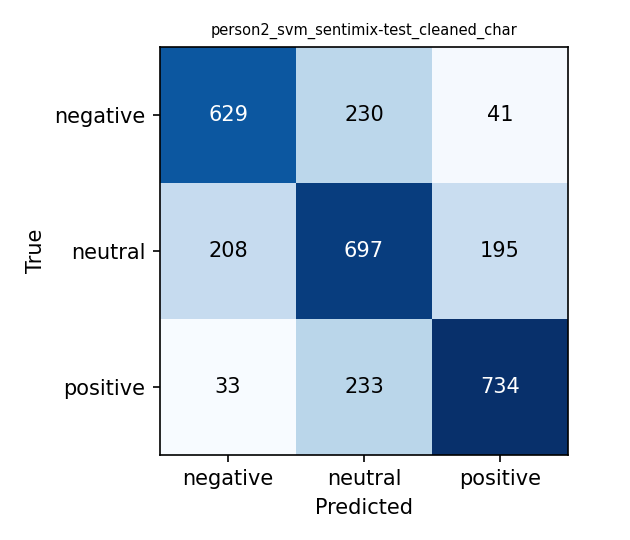

In [48]:
import sys; sys.path.insert(0, ".")
import pandas as pd
from IPython.display import Image, display
from src.evaluate import load_results

res = load_results()
test = res[res.dataset == "sentimix_test"].drop_duplicates("run_id", keep="last").copy()
test["dict_size"] = test.dict_size.fillna("").astype(str)
main = test[(test.preprocessing != "normalized") | test.dict_size.isin(["all", ""])]   # leave out the dictionary-size runs
main = main[main.model.isin(["logreg", "svm", "naive_bayes", "decision_tree"]) & main.features.isin(["word", "char"])]

grid = main.pivot_table(index="model", columns=["features", "preprocessing"], values="macro_f1", aggfunc="last")
grid = grid.reindex(index=["svm", "logreg", "naive_bayes", "decision_tree"],
                    columns=pd.MultiIndex.from_product([["word", "char"], ["raw", "cleaned", "normalized"]]))
print(f"Standard runs done: {int(grid.notna().sum().sum())} of 24")
display(grid.round(4))

best = main.sort_values("macro_f1").iloc[-1]
print(f"Best test macro-F1: {best.macro_f1:.4f}  ({best.run_id})")
display(Image(f"results/confusion/{best.run_id}.png", width=380))

## 6. First research results

### 6.1 Build the slices (Persons 1 and 4)
Labels every val and test tweet: how mixed it is (code-mixing index), negation, spelling variants, length and emoji.

In [55]:
!python3 -m src.slices


val: wrote data/processed/slices_val.csv (3000 tweets), mean CMI 21.9
  cmi_level    low: 1497  medium: 867  high: 636
  negation     no: 2060  yes: 940
  spelling_var no: 1699  yes: 1301
  length       short: 336  medium: 1379  long: 1285
  emoji        no: 2442  yes: 558

test: wrote data/processed/slices_test.csv (3000 tweets), mean CMI 21.7
  cmi_level    low: 1544  medium: 832  high: 624
  negation     no: 2104  yes: 896
  spelling_var no: 1736  yes: 1264
  length       short: 332  medium: 1356  long: 1312
  emoji        no: 2410  yes: 590


### 6.2 Make the tables and charts
Run after all the runs in section 4. It prints every table here and saves them in `results/tables/` and `results/figures/`.

In [56]:
!python3 scripts/make_tables.py


== q1_preprocessing ==
              model features    raw  cleaned  normalized  change_raw_to_normalized
      Complement NB     word 0.6398      NaN         NaN                       NaN
      Decision tree     char 0.5385   0.5508      0.5233                   -0.0152
      Decision tree     word 0.5243   0.5296      0.5494                    0.0251
         Linear SVM     char 0.6826   0.6909      0.6905                    0.0079
         Linear SVM     word 0.6765   0.6701      0.6781                    0.0016
Logistic regression     char 0.6716   0.6839      0.6904                    0.0188
Logistic regression     word 0.6762   0.6667      0.6685                   -0.0077
        Naive Bayes     char 0.6457   0.6625      0.6649                    0.0192
        Naive Bayes     word 0.6693   0.6730      0.6768                    0.0075

== q1_significance ==
              model features            comparison    change    low_95   high_95        real_change
      Decision tree    

### 6.3 Q1 · Does cleaning and normalizing the text help? (Person 2)
* **Bars:** test macro-F1 for raw, cleaned and normalized text.
* **Significance table:** *real_change = yes* means the improvement is unlikely to be luck (paired bootstrap, 95%).
* **Line:** how macro-F1 changes as the dictionary grows.

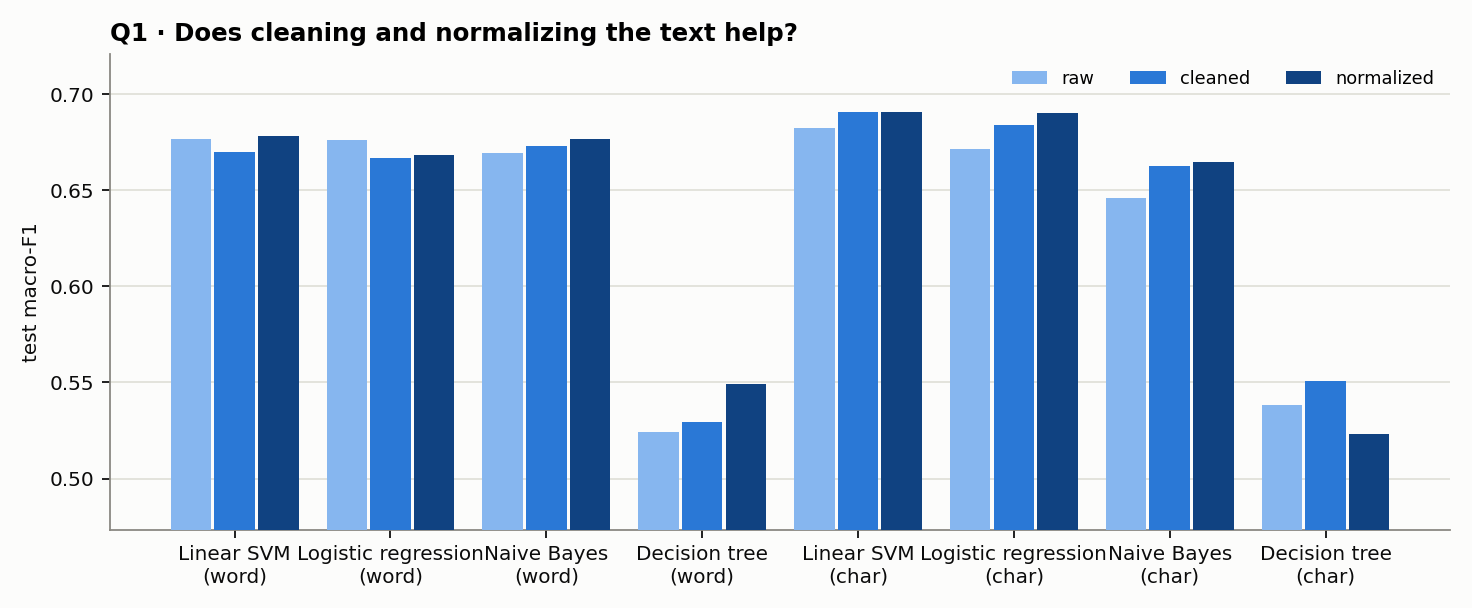

,model,features,comparison,change,low_95,high_95,real_change
0,Decision tree,char,raw -> cleaned,0.0123,-0.0081,0.0323,no (could be luck)
1,Decision tree,char,cleaned -> normalized,-0.0275,-0.0453,-0.0086,yes
2,Decision tree,char,raw -> normalized,-0.0152,-0.0361,0.0053,no (could be luck)
3,Decision tree,word,raw -> cleaned,0.0053,-0.0151,0.0241,no (could be luck)
4,Decision tree,word,cleaned -> normalized,0.0198,-0.0016,0.0401,no (could be luck)
5,Decision tree,word,raw -> normalized,0.0251,0.0049,0.0459,yes
6,Linear SVM,char,raw -> cleaned,0.0083,-0.0030,0.0195,no (could be luck)
7,Linear SVM,char,cleaned -> normalized,-0.0004,-0.0071,0.0070,no (could be luck)
8,Linear SVM,char,raw -> normalized,0.0079,-0.0036,0.0208,no (could be luck)
9,Linear SVM,word,raw -> cleaned,-0.0064,-0.0155,0.0023,no (could be luck)


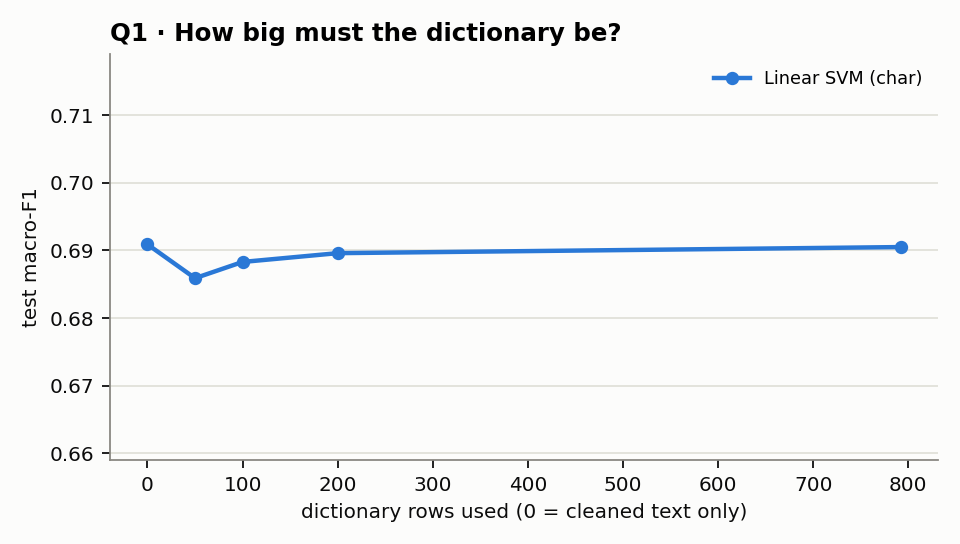

In [57]:
from IPython.display import Image, display
import pandas as pd

display(Image("results/figures/q1_preprocessing.png", width=900))
sig = pd.read_csv("results/tables/q1_significance.csv")
display(sig.round(4))
display(Image("results/figures/q1_dict_size.png", width=560))

### 6.4 Q2 · Which tweets make the models fail? (Persons 1 and 4)
Each model is represented by its run with the best **validation** score.
Each cell is the slice's macro-F1 minus the model's overall macro-F1: **red = the model does worse on those tweets**.

Linear SVM: person2_svm_sentimix-test_cleaned_char (val 0.6281, test 0.6909)
Logistic regression: person1_logreg_sentimix-test_cleaned_char (val 0.6227, test 0.6839)
Naive Bayes: person3_naive-bayes_sentimix-test_cleaned_word (val 0.6126, test 0.6730)
Complement NB: person3_complement-nb_sentimix-test_raw_word (val 0.5874, test 0.6398)
Decision tree: person4_decision-tree_sentimix-test_normalized_word_dall_s42 (val 0.5138, test 0.5494)



,slice,level,n_tweets,Linear SVM,Logistic regression,Naive Bayes,Complement NB,Decision tree
0,ALL,all test tweets,3000,0.6909,0.6839,0.6730,0.6398,0.5494
1,cmi_level,low,1544,0.6785,0.6787,0.6763,0.6215,0.5565
2,cmi_level,medium,832,0.7014,0.6849,0.6585,0.6344,0.5340
3,cmi_level,high,624,0.6719,0.6635,0.6409,0.6574,0.5269
4,negation,no,2104,0.6989,0.6914,0.6902,0.6544,0.5571
5,negation,yes,896,0.6047,0.5939,0.5815,0.5474,0.4668
6,spelling_var,no,1736,0.6792,0.6741,0.6633,0.6322,0.5553
7,spelling_var,yes,1264,0.6994,0.6890,0.6743,0.6416,0.5292
8,length,short,332,0.7654,0.7335,0.7176,0.6689,0.5489
9,length,medium,1356,0.6963,0.6954,0.6949,0.6541,0.5686


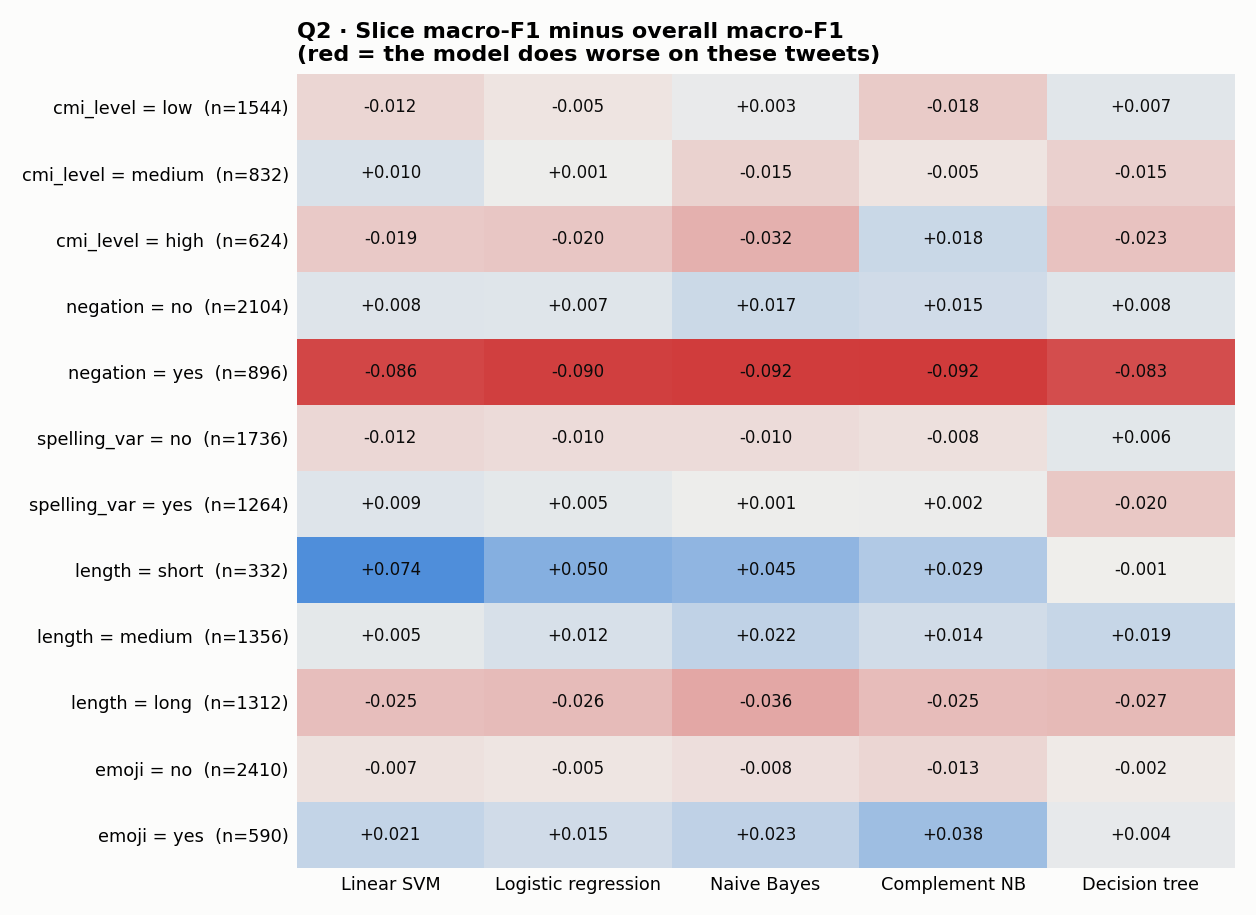

In [58]:
from IPython.display import Image, display
import pandas as pd

print(open("results/tables/q2_runs_used.txt").read())
display(pd.read_csv("results/tables/q2_slices.csv").round(4))
display(Image("results/figures/q2_slices_heatmap.png", width=760))